# QUEST airborne gravity: an audited 2D workflow

Actual data from Geoscience BC Report 2008-08, acquired and processed by Sander Geophysics. This notebook reviews the executed Python workflow and recomputes selected checks. Read `docs/METHODS.md` and `docs/METADATA_ISSUES.md` before interpreting the products. Initial implementation prepared with AI assistance.

**First run:** from the repository root, install the package, run `python -m quest_gravity.download`, then `python -m quest_gravity.pipeline`. The pipeline performs the complete numerical analysis; this notebook explains and inspects the resulting files.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from quest_gravity.core import read_quest_grid, metrics
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Start this notebook in the project root or notebooks folder'
OUT = ROOT / 'outputs'
meta = json.loads((OUT / 'metadata.json').read_text())
q = meta['qc']
pd.Series({key:q[key] for key in ['rows_parsed','line_sections','blocks','planned_traverse_lines','duplicate_time_line_records','utc_seconds_above_86400']})

Out[0]: 
rows_parsed                    1049547
line_sections                      340
blocks                           79791
planned_traverse_lines             246
duplicate_time_line_records          0
utc_seconds_above_86400          43663
dtype: int64


## 1. Audit the data

A coordinate/reference-system conflict, binary-versus-ASCII format conflict and ambiguous channel descriptions required explicit decisions. A geographic-to-projected check supports UTM zone 10N; the metre-scale discrepancy is not the survey's positional accuracy. The data already contain physical corrections and filtering. Applying them again would be wrong.

In [2]:
display(pd.Series(q['crs_check']))
display(pd.read_csv(OUT / 'tables/supplier_grid_consistency.csv'))
display(Markdown((ROOT / 'docs/METADATA_ISSUES.md').read_text()))

n                                                                  10496
median_difference_m                                             1.302552
max_difference_m                                                1.311513
note                   Modern EPSG transformation versus supplied WGS...
dtype: object

,file,line_channel,n,bias_mgal,mae_mgal,rmse_mgal,p95_abs_mgal
0,GRVBG3.5KM.grd,GRVBGL3.5,10493,-0.000073,0.003475,0.004456,0.008771
1,GRVFA3.5KM.grd,GRVFRAL3.5,10493,-0.000175,0.007642,0.011085,0.024072
2,ISOBG3.5KM.grd,ISOBGL3.5,10493,-0.000056,0.003476,0.004466,0.008670


# Metadata audit and decisions

This audit is part of the analysis, not a claim to have corrected the supplier's archive.
The original files remain untouched. See `outputs/metadata.json` and the CSV tables
for measured checks. Source: Geoscience BC Report 2008-08 and archive ReadMe.txt.

| Issue | Evidence | Decision |
|---|---|---|
| Projection conflict | README and XYZ headings specify NAD83 / UTM 10N; report printed p.22 says zone 32 North. | Use EPSG:26910. Compare a systematic sample of supplied geographic and projected coordinates. The observed ~1.3 m discrepancy is consistent with a reference-frame/realization difference at this scale, but its origin is not established. It is not survey accuracy. |
| File-format conflict | Report p.22 calls the grids GXF ASCII; released `.grd` files have binary headers and float32 payloads. | Use a guarded reader for this release's exact uncompressed encoding. Reject other encodings. Verify orientation and values against corresponding line channels before export. |
| Ambiguous final line-channel descriptions | README calls both GRVFRAL3.5 and GRVBGL3.5 isostatically corrected, while grid descriptions distinguish free-air, Bouguer and isostatic products. | Keep original channel names. Match each line channel to the corresponding independently labelled supplied grid and test the numerical identity ISOBGL3.5 approximately equals GRVBGL3.5 minus ISOCORR. Treat the final Bouguer grid as the supplier's Bouguer product; do not apply the isostatic correction twice. |
| Simple versus terrain-corrected terminology | The line table calls GRVBGL100 simple Bouguer, but the processing narrative includes terrain and curvature corrections. Numerically, GRVBGL100 is not simply GRVFRAL100 minus SBGCOR. | Call it the supplier's line-filtered Bouguer channel, preserve its name, and document the incomplete correction decomposition. Do not assert that we calculated complete or simple Bouguer gravity ourselves. Ask the supplier/PI before correction-sensitive reuse. |
| Filter description conflict | Narrative p.17 mentions a 42 s half-wavelength line filter; channel names/README describe 100 s full-wavelength filtering. Spatial cutoff descriptions also mix half/full wavelengths. | Preserve channel-specific README labels. Report the published final spatial filter as 3.5 km half-wavelength. Do not reconstruct the exact supplier transfer function or equate node spacing with resolving power. |
| Time representation | Some SECOND values exceed 86,400 although labelled seconds past midnight. | Count and flag them. This spatial analysis does not use derived timestamps or velocities. Resolve day rollover before time-dependent reprocessing. |

## What must be confirmed for a navigation study

Determine the vertical reference and observation surface, exact reduction history,
gravity functional (anomaly versus disturbance), reference normal field, and whether
terrain/long-wavelength components must be restored for the sensor model. These
are not solved by renaming a Bouguer raster. Confirm definitions with the PI before
simulating a physical airborne measurement along a trajectory.


## 2. Inspect three distinct supplier products

The Bouguer field, free-air field and isostatic residual answer different questions. Values are mGal; 1 mGal = 1e-5 m/s². A 250 m output lattice does not recover wavelengths removed by supplier filtering.

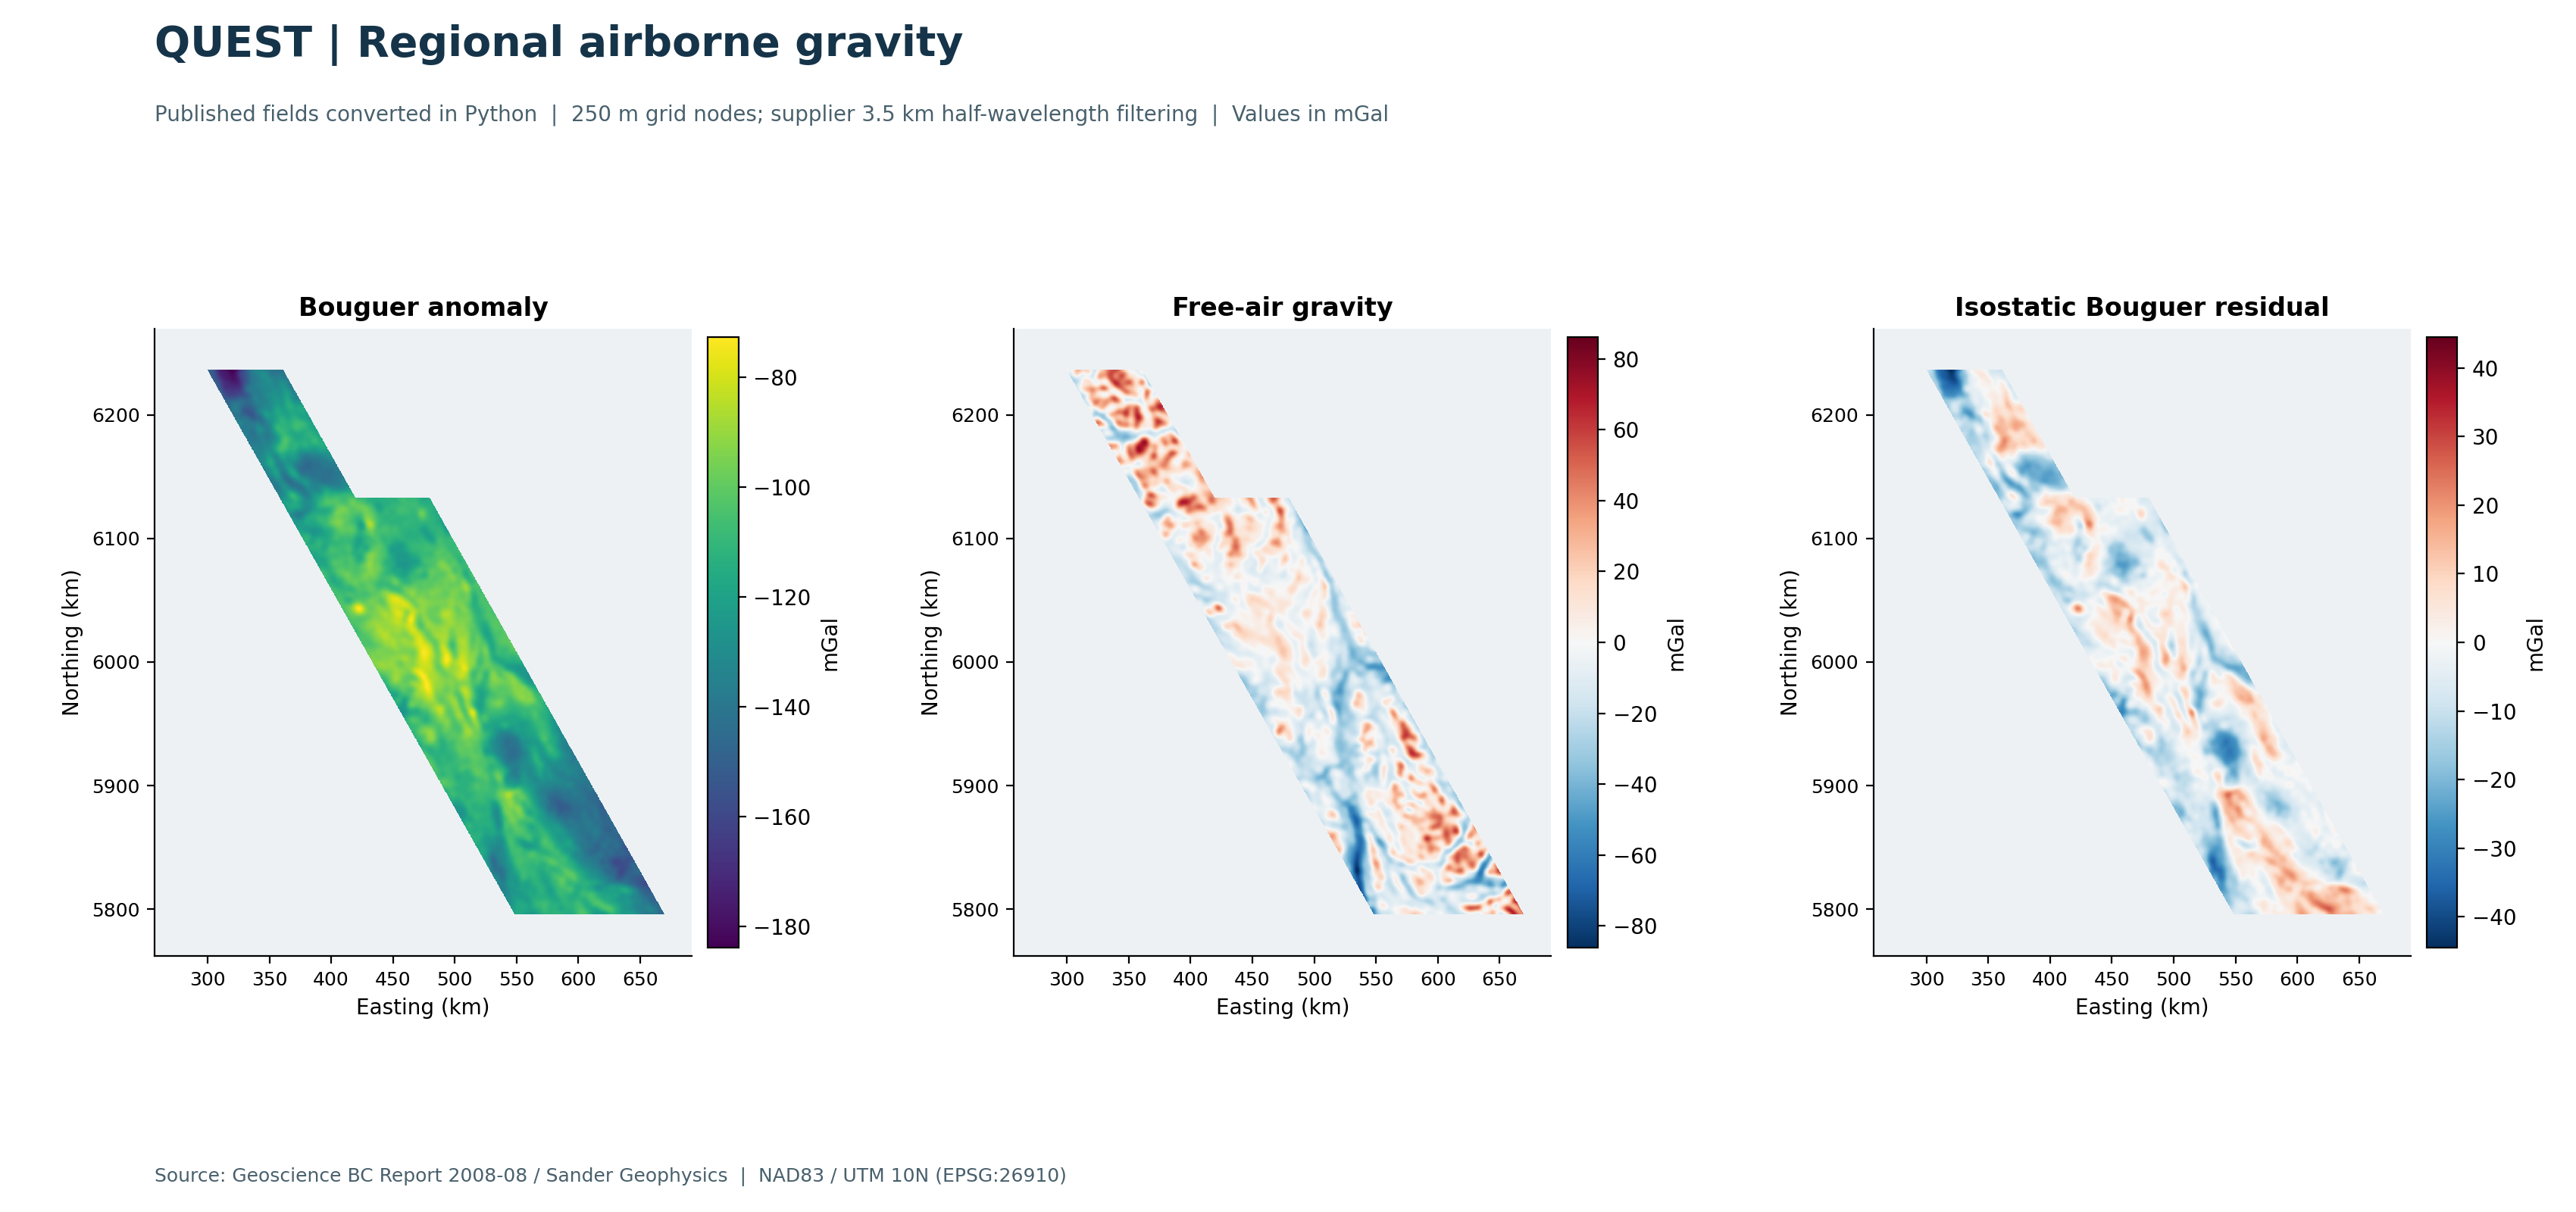

In [3]:
display(Image(filename=str(OUT / 'figures/01_gravity_atlas.png'), width=1100))

## 3. Recompute a source-grid check

The guarded reader is specific to the released uncompressed binary format. It does not claim to support all Geosoft GRD variants.

In [4]:
x, y, z = read_quest_grid(ROOT / 'data/raw/release/GBCReport2008-8_Gravity_Data/GRVBG3.5KM.grd')
pd.Series({'x_nodes':len(x),'y_nodes':len(y),'spacing_m':x[1]-x[0],
           'valid_nodes':int(np.isfinite(z).sum()),'min_mgal':np.nanmin(z),'max_mgal':np.nanmax(z)})

Out[0]: 
x_nodes          1738.000000
y_nodes          2032.000000
spacing_m         250.000000
valid_nodes    755398.000000
min_mgal         -183.925919
max_mgal          -72.725304
dtype: float64


## 4. Build a second product from line-filtered data

The pipeline preserves each exact line section during 500 m block averaging, then interpolates the GRVBGL100 channel. Support masks prevent extrapolation and limit bridging large gaps. Distance to data is not formal uncertainty.

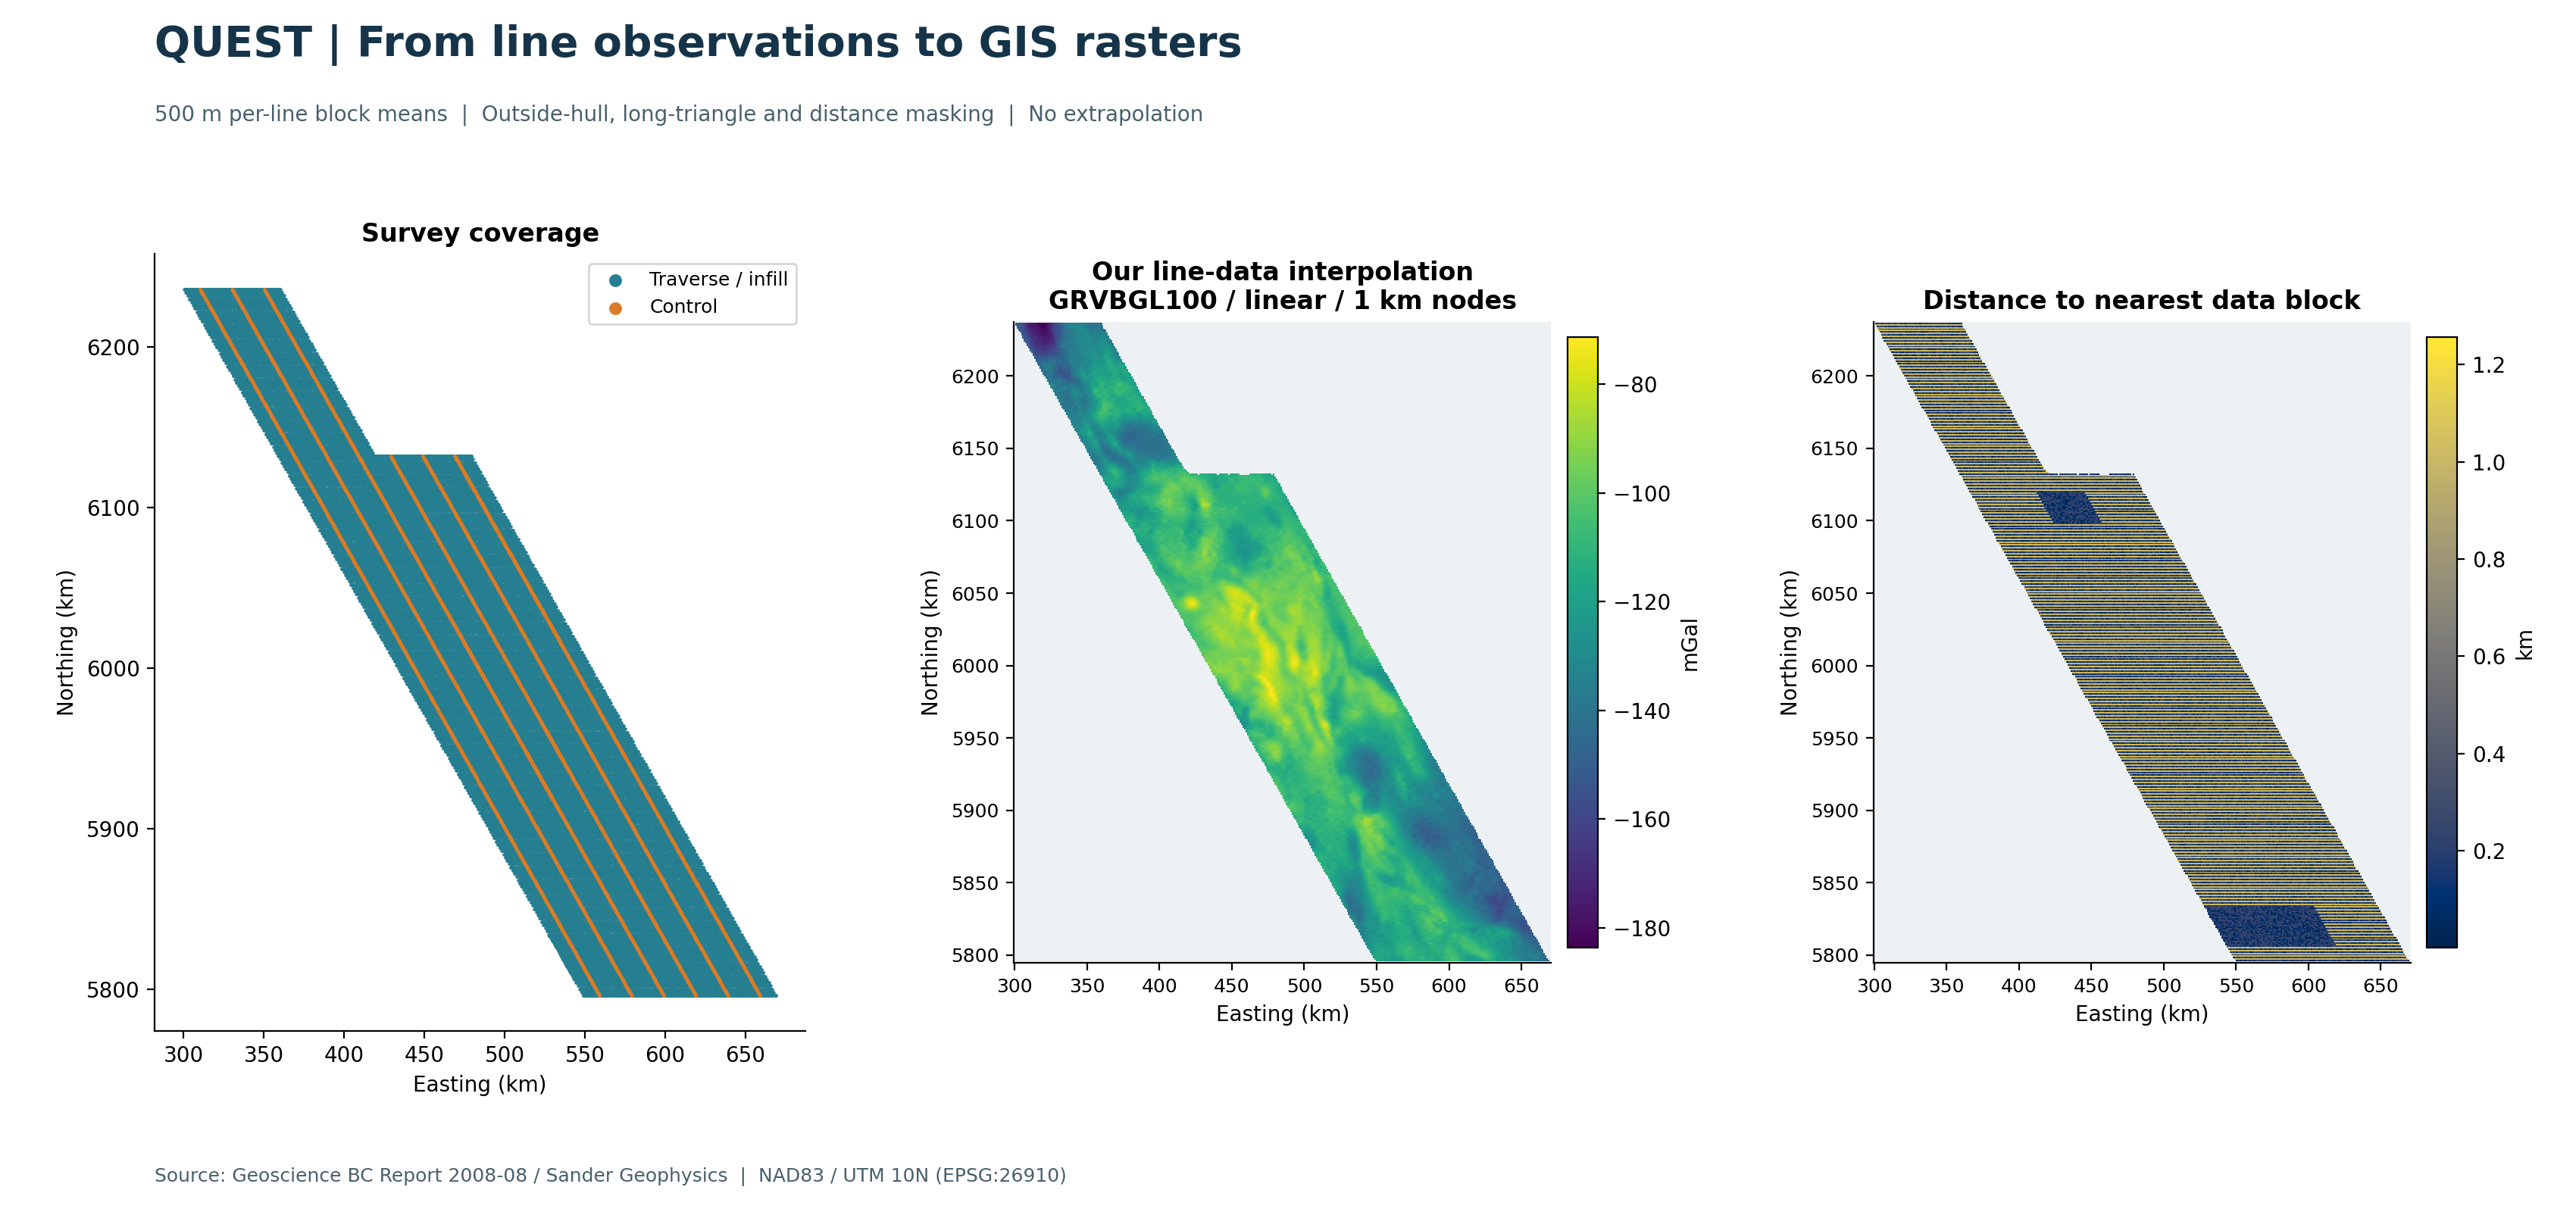

,LINE,bx,by,easting_m,northing_m,bouguer_mgal,free_air_mgal,count,planned_line
0,101.0,780,12187,390493.700000,6.093986e+06,-112.680000,-10.620000,1,101
1,101.0,780,12188,390345.049565,6.094255e+06,-111.679565,-8.846087,23,101
2,101.0,780,12189,390154.795714,6.094587e+06,-110.267143,-6.291429,7,101
3,101.0,781,12186,390884.631667,6.093297e+06,-113.983889,-12.910000,18,101
4,101.0,781,12187,390632.096190,6.093742e+06,-113.329524,-11.764286,21,101
5,101.0,782,12184,391414.120909,6.092355e+06,-113.629091,-11.975455,11,101
6,101.0,782,12185,391190.096500,6.092756e+06,-113.947000,-12.751500,20,101
7,101.0,782,12186,391025.306667,6.093044e+06,-114.066667,-13.043333,3,101
8,101.0,783,12182,391948.901667,6.091423e+06,-112.858333,-9.133333,6,101
9,101.0,783,12183,391762.965263,6.091751e+06,-113.077368,-10.208947,19,101


In [5]:
display(Image(filename=str(OUT / 'figures/03_line_processing.png'), width=1100))
display(pd.read_csv(OUT / 'tables/line_blocks.csv.gz',nrows=10))

## 5. Withhold whole planned lines

Random sample splits would retain near-neighbours from the same track. Five interleaved folds instead keep all sections/reflights together. The supplier has already used survey-wide information in levelling, so these remain conditional interpolation scores. Unpredicted blocks remain in the coverage denominator.

,method,n,bias_mgal,mae_mgal,rmse_mgal,p95_abs_mgal,coverage_fraction,median_line_rmse_mgal,lines_scored
0,linear,70844,-0.010802,1.454815,1.911687,3.956561,0.987758,1.832260,244
1,idw,70844,-0.007158,1.475586,1.933544,3.993487,0.987758,1.878439,244
2,nearest,70844,-0.001566,2.272911,2.980822,6.009812,0.987758,2.865645,244


n               70844.000000
bias_mgal          -0.010802
mae_mgal            1.454815
rmse_mgal           1.911687
p95_abs_mgal        3.956561
dtype: float64

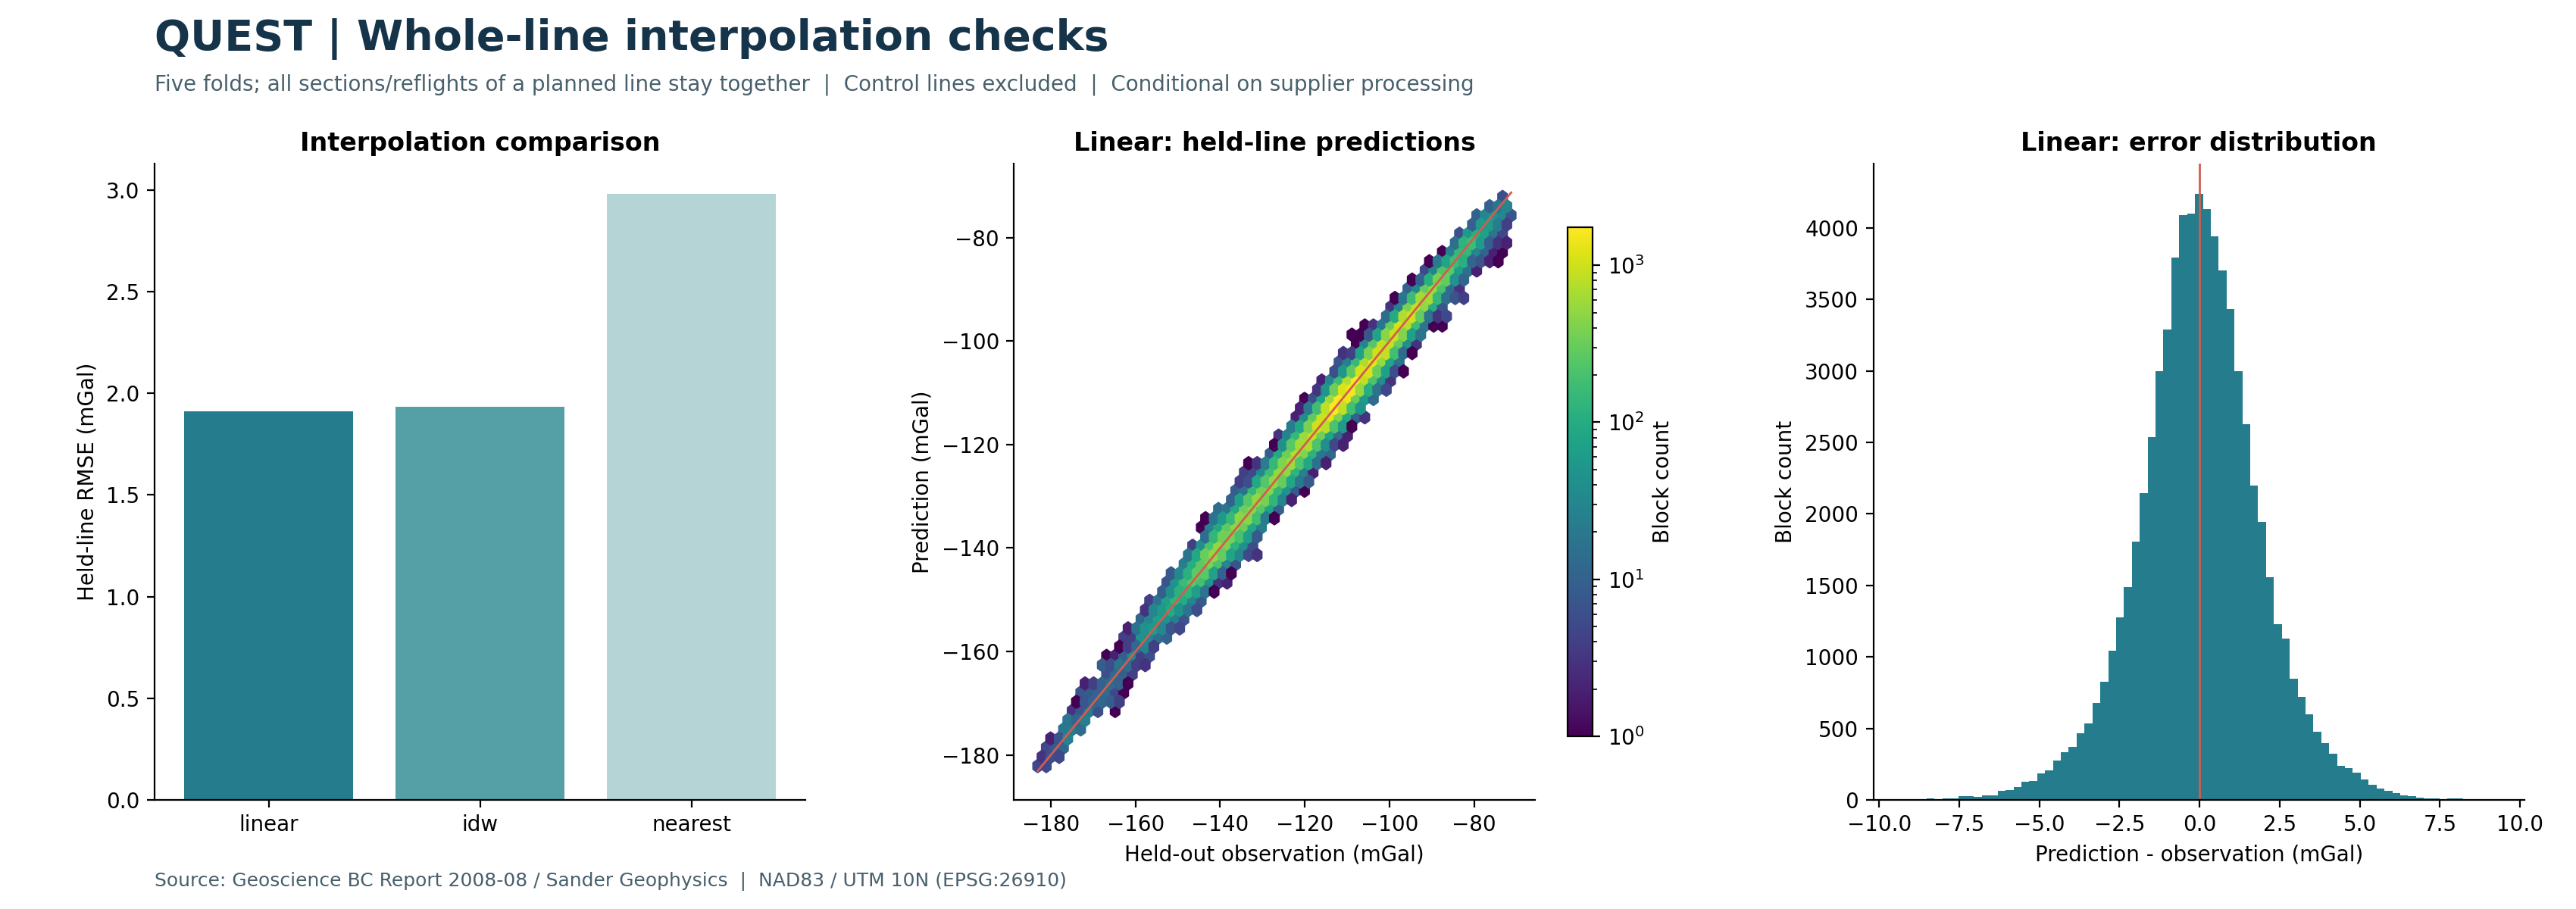

In [6]:
scores=pd.read_csv(OUT / 'tables/cv_summary.csv')
display(scores)
predictions=pd.read_csv(OUT / 'tables/cv_predictions.csv.gz')
linear=predictions[predictions.method=='linear']
check=metrics(linear.predicted_mgal-linear.observed_mgal)
assert np.isclose(check['rmse_mgal'],scores.set_index('method').loc['linear','rmse_mgal'])
display(pd.Series(check))
display(Image(filename=str(OUT / 'figures/04_validation.png'), width=1100))

## 6. Explore scale and spatial structure

The Gaussian residual is an exploratory decomposition, not an isostatic anomaly. A 95% kernel-support threshold intentionally removes much of the edge. A 30 km sigma has no supported cells under that criterion. Horizontal gradients describe local map variation; they do not prove unique position observability.

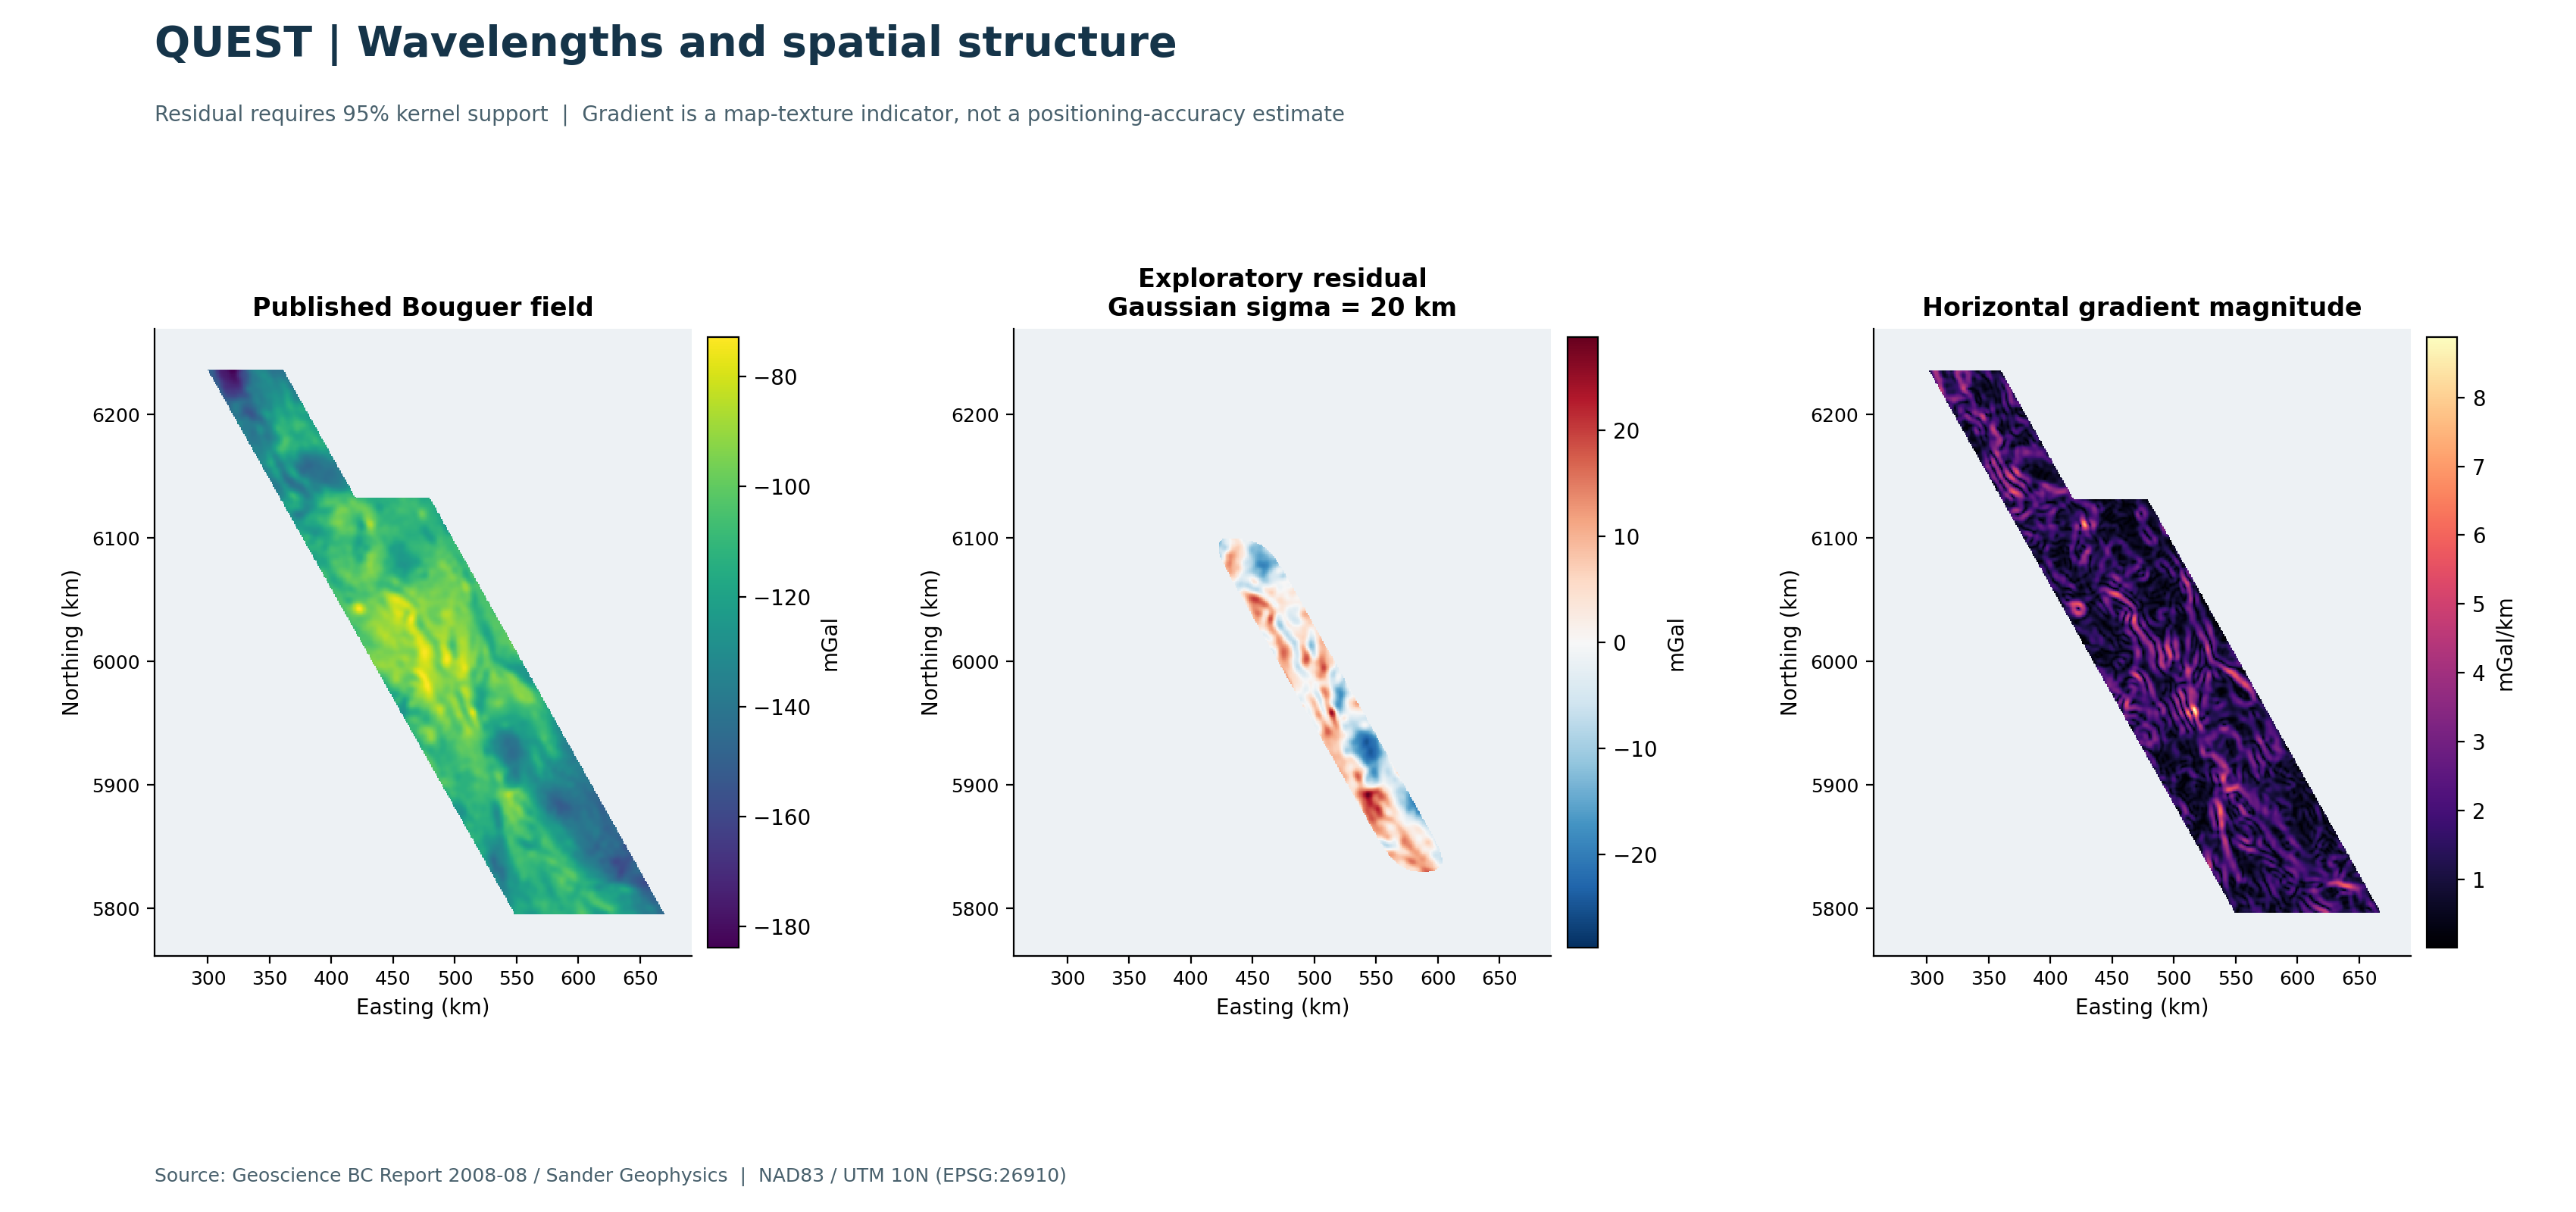

,sigma_km,common_cells,std_mgal,min_mgal,max_mgal
0,10,11969,6.203935,-16.217020,23.168440
1,15,11969,7.985785,-20.607921,25.990437
2,20,11969,9.221675,-24.805347,28.826508


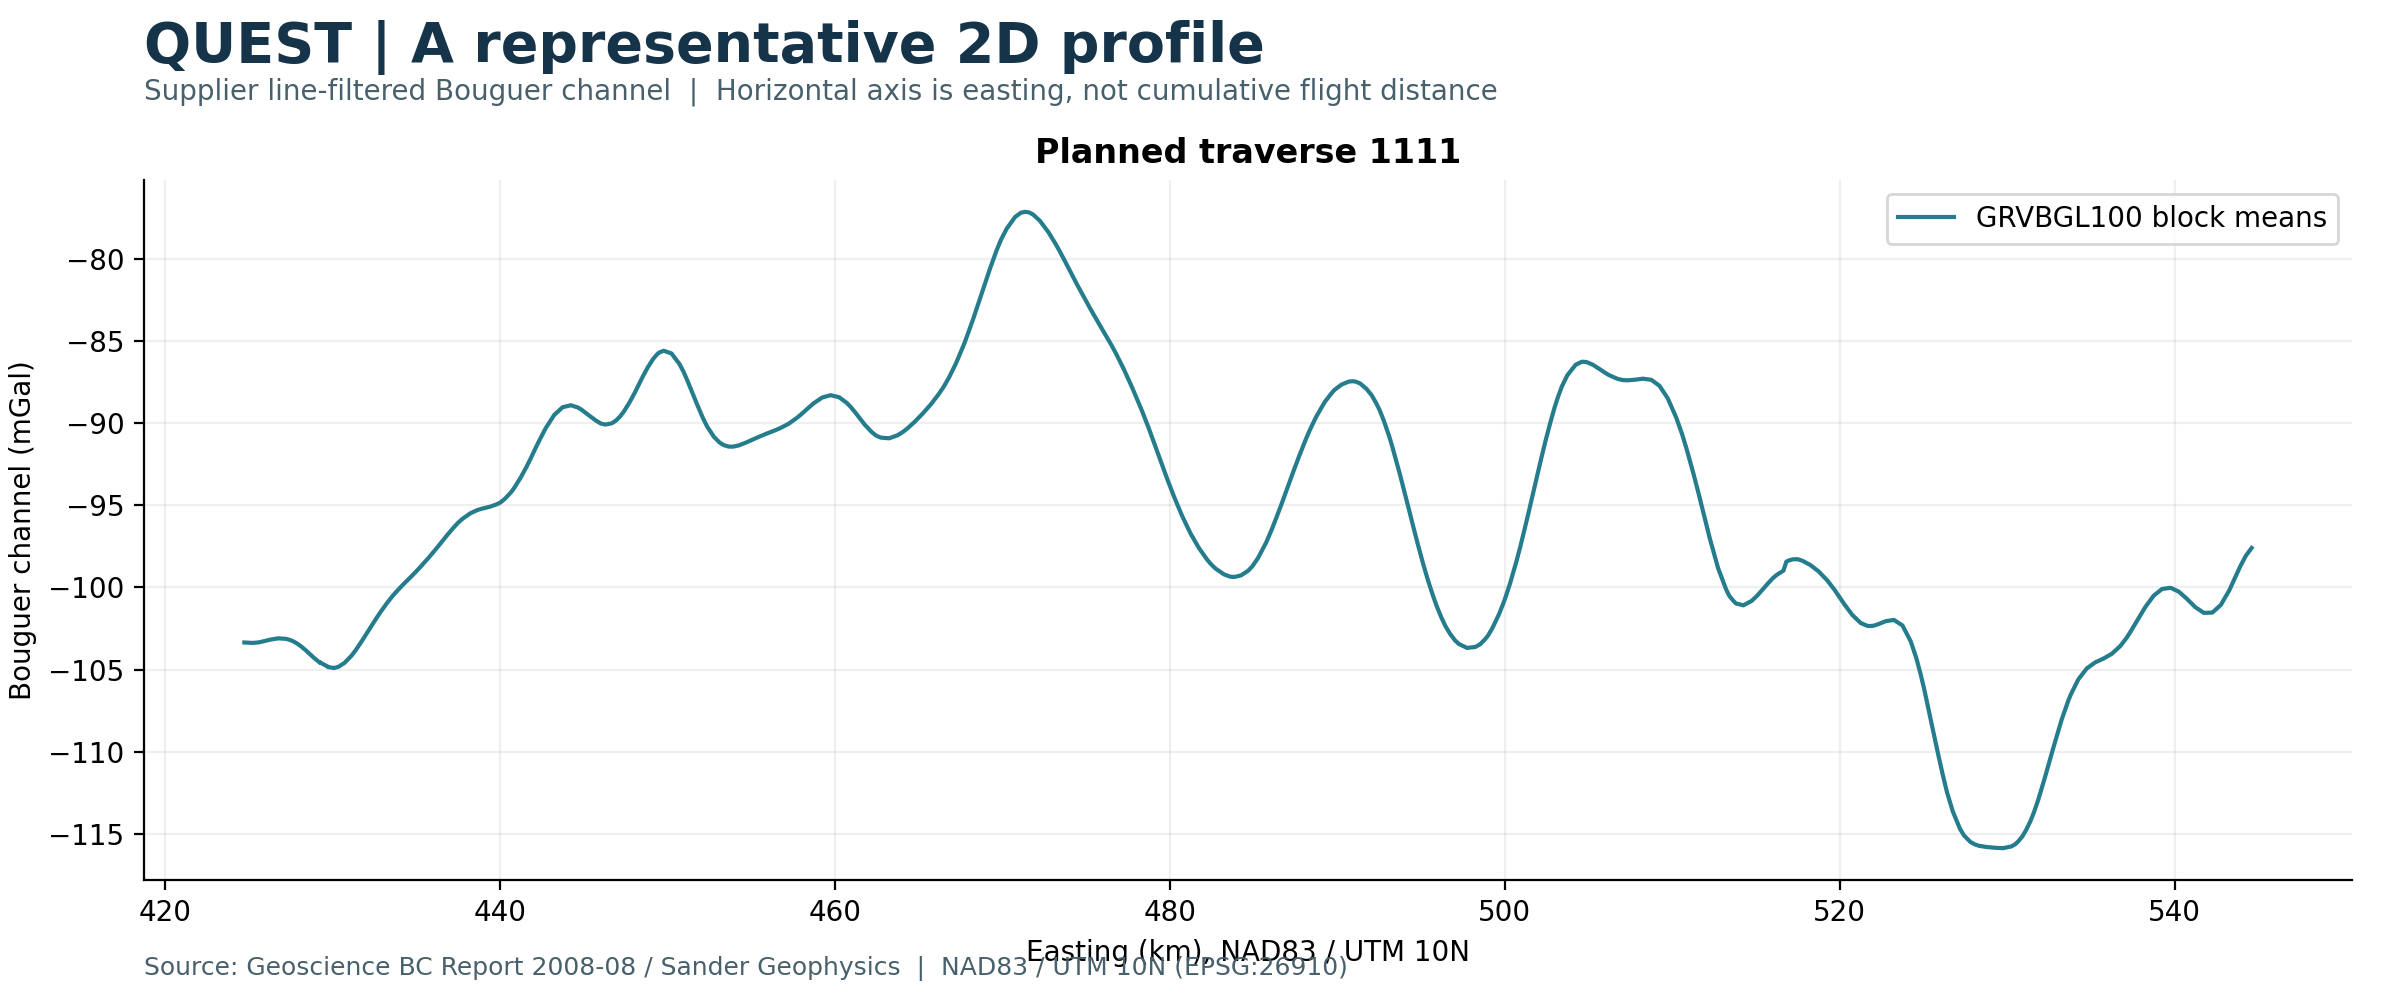

In [7]:
display(Image(filename=str(OUT / 'figures/02_spatial_analysis.png'), width=1100))
display(pd.read_csv(OUT / 'tables/regional_scale_sensitivity.csv'))
display(Image(filename=str(OUT / 'figures/05_profile.png'), width=1000))

## 7. Review the GIS export

GeoTIFFs use northern-first row order, correctly located node centres, EPSG:26910 and explicit no-data. Open these products in QGIS and compare source-grid and line-data products with attention to their different filtering histories.

In [8]:
import rasterio
with rasterio.open(OUT / 'grids/bouguer100_linear_1000m.tif') as ds:
    display(pd.Series({'CRS':str(ds.crs),'shape':ds.shape,'resolution':ds.res,
                       'upper_left_node':ds.xy(0,0),'nodata':ds.nodata,'units':ds.tags().get('units')}))

CRS                           EPSG:26910
shape                         (443, 371)
resolution              (1000.0, 1000.0)
upper_left_node    (300000.0, 6237000.0)
nodata                           -9999.0
units                               mGal
dtype: object

## Next experiment

Agree with the PI on the intended gravity functional and observation height. Confirm correction details and introduce independent reference data before operational navigation claims. For this project, first repeat the analysis with a labelled blocking/support sensitivity experiment and explain what changes. Keep the baseline results unchanged.

The figures and measured tables above are generated from the actual release. The notebook does not create a synthetic map or claim raw-sensor processing.